# AI use by firm size: Turkey and the EU

**How much less likely are small firms to use AI than large firms, is the gap closing, and what holds non-users back?**

This notebook rebuilds the processed tables from the raw readings, recomputes every headline figure and checks it against the build script output.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT / 'scripts'))
import build_data
raw, tidy, use, head = build_data.build()
print(f'{len(raw)} readings from {raw.source_id.nunique()} documents, {len(tidy)} figures')

110 readings from 13 documents, 41 figures


## 1. Data checks

Row count, missing values, duplicates, value range and coverage by economy and measure.

In [2]:
print('missing values:', int(raw.isna().sum().sum() - raw.note.isna().sum()))
print('duplicate readings:', int(raw.duplicated(['economy','year','measure','item','source_id']).sum()))
print('value range:', tidy.value.min(), 'to', tidy.value.max())
print('set-aside readings:', int(raw.note.fillna('').str.startswith('set_aside').sum()))
tidy.groupby(['economy','measure','year']).size().rename('figures').reset_index()

missing values: 0
duplicate readings: 0
value range: 2.3 to 74.2
set-aside readings: 5


,economy,measure,year,figures
0,EU-27,ai_use,2023,1
1,EU-27,ai_use,2024,4
2,EU-27,ai_use,2025,4
3,EU-27,considered_not_used,2025,4
4,EU-27,purpose,2025,3
5,EU-27,reason_not_used,2025,3
6,Turkey,ai_use,2021,4
7,Turkey,ai_use,2025,4
8,Turkey,considered_not_used,2025,4
9,Turkey,purpose,2025,7


In [3]:
tidy.verification.value_counts()

verification
two-or-more-documents    34
one-document              7
Name: count, dtype: int64

## 2. AI use by size class

In [4]:
use

,economy,year,small_pct,medium_pct,large_pct,all_pct,gap_large_minus_small_pts,ratio_large_to_small
1,EU-27,2024,11.21,20.97,41.17,13.48,29.96,3.67
2,EU-27,2025,17.00,30.36,55.03,19.95,38.03,3.24
3,Turkey,2021,2.30,3.60,9.60,2.70,7.30,4.17
4,Turkey,2025,6.60,9.60,24.10,7.50,17.50,3.65


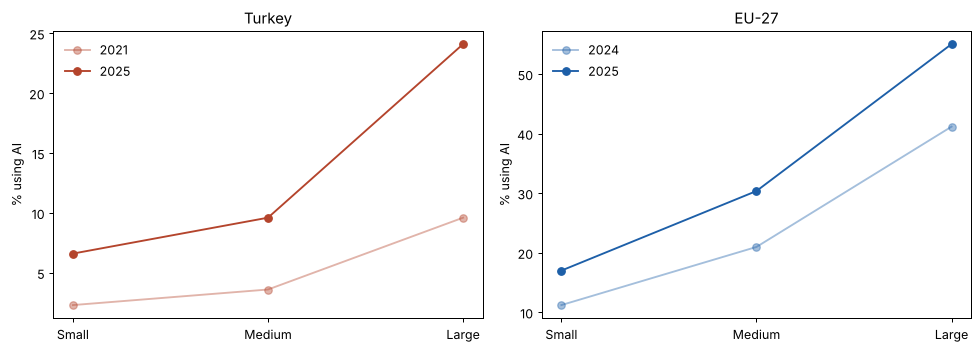

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, (econ, colour) in zip(axes, [('Turkey', '#b4442c'), ('EU-27', '#1d5fa8')]):
    d = use[use.economy == econ]
    for _, r in d.iterrows():
        alpha = 1 if r.year == 2025 else 0.4
        ax.plot(['Small','Medium','Large'], [r.small_pct, r.medium_pct, r.large_pct], marker='o', color=colour, alpha=alpha, label=int(r.year))
    ax.set_title(econ); ax.set_ylabel('% using AI'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Recompute the headline figures and assert they match the build output

In [6]:
def v(e, y, m, i):
    return tidy[(tidy.economy==e)&(tidy.year==y)&(tidy.measure==m)&(tidy['item']==i)].value.iloc[0]
S, M, L = 'Small (10-49)', 'Medium (50-249)', 'Large (250+)'
check = {
 'turkey_small_2025': v('Turkey',2025,'ai_use',S),
 'turkey_large_2025': v('Turkey',2025,'ai_use',L),
 'turkey_ratio_2025': round(v('Turkey',2025,'ai_use',L)/v('Turkey',2025,'ai_use',S), 2),
 'turkey_gap_2021': round(v('Turkey',2021,'ai_use',L)-v('Turkey',2021,'ai_use',S), 2),
 'turkey_gap_2025': round(v('Turkey',2025,'ai_use',L)-v('Turkey',2025,'ai_use',S), 2),
 'eu_small_2025': v('EU-27',2025,'ai_use',S),
 'eu_large_2025': v('EU-27',2025,'ai_use',L),
 'eu_ratio_2025': round(v('EU-27',2025,'ai_use',L)/v('EU-27',2025,'ai_use',S), 2),
 'eu_gap_2024': round(v('EU-27',2024,'ai_use',L)-v('EU-27',2024,'ai_use',S), 2),
 'eu_gap_2025': round(v('EU-27',2025,'ai_use',L)-v('EU-27',2025,'ai_use',S), 2),
 'eu_small_rise_pts': round(v('EU-27',2025,'ai_use',S)-v('EU-27',2024,'ai_use',S), 2),
 'eu_large_rise_pts': round(v('EU-27',2025,'ai_use',L)-v('EU-27',2024,'ai_use',L), 2),
 'turkey_expertise_reason': v('Turkey',2025,'reason_not_used','Lack of relevant expertise'),
 'eu_expertise_reason': v('EU-27',2025,'reason_not_used','Lack of relevant expertise'),
 'turkey_marketing_purpose': v('Turkey',2025,'purpose','Marketing or sales'),
 'eu_marketing_purpose': v('EU-27',2025,'purpose','Marketing or sales'),
}
saved = pd.read_csv(ROOT/'data'/'processed'/'headline_figures.csv').set_index('figure').value
for k, val in check.items():
    assert abs(saved[k] - val) < 1e-9, (k, saved[k], val)
print('all', len(check), 'headline figures match the build script output')
pd.Series(check, name='value')

all 16 headline figures match the build script output


turkey_small_2025            6.60
turkey_large_2025           24.10
turkey_ratio_2025            3.65
turkey_gap_2021              7.30
turkey_gap_2025             17.50
eu_small_2025               17.00
eu_large_2025               55.03
eu_ratio_2025                3.24
eu_gap_2024                 29.96
eu_gap_2025                 38.03
eu_small_rise_pts            5.79
eu_large_rise_pts           13.86
turkey_expertise_reason     74.20
eu_expertise_reason         70.89
turkey_marketing_purpose    46.50
eu_marketing_purpose        34.70
Name: value, dtype: float64

## 4. Growth by size class

Small firms grew fastest in percent, large firms grew most in points.

In [7]:
rows = []
for econ, y0 in [('Turkey', 2021), ('EU-27', 2024)]:
    for s in [S, M, L]:
        a, b = v(econ, y0, 'ai_use', s), v(econ, 2025, 'ai_use', s)
        rows.append((econ, s, y0, a, b, round(b-a, 2), round(100*(b-a)/a, 1)))
pd.DataFrame(rows, columns=['economy','size','from_year','from_pct','to_pct_2025','change_pts','change_pct'])

,economy,size,from_year,from_pct,to_pct_2025,change_pts,change_pct
0,Turkey,Small (10-49),2021,2.30,6.60,4.30,187.0
1,Turkey,Medium (50-249),2021,3.60,9.60,6.00,166.7
2,Turkey,Large (250+),2021,9.60,24.10,14.50,151.0
3,EU-27,Small (10-49),2024,11.21,17.00,5.79,51.7
4,EU-27,Medium (50-249),2024,20.97,30.36,9.39,44.8
5,EU-27,Large (250+),2024,41.17,55.03,13.86,33.7


## 5. Who considered AI but did not use it, and why

In [8]:
tidy[tidy.measure=='considered_not_used'].pivot(index='item', columns='economy', values='value')

In [9]:
tidy[tidy.measure=='reason_not_used'][['economy','item','value','verification']].sort_values(['economy','value'], ascending=[False, False])

In [10]:
tidy[tidy.measure=='purpose'][['economy','item','value','verification']].sort_values(['economy','value'], ascending=[False, False])